# Project 3 — Which export measure best predicts growth?
Julia Wang · Started November 13, 2026

Compare simple diversification measures and standard HS4 ECI as predictors of subsequent real GDP-per-capita growth. The initial horse race is followed by HS2 and grouped aggregation tests, Fitness, continuous-RCA ECI, additional historical origins, five-year outcomes, error diagnostics and a qualified recommendation.

Source assignment: `willbetts/ECI_growth_prediction.md`. All numerical findings below are generated from executed cells. Historical data are revised releases, so this is a held-out-period comparison rather than a reconstruction of unrevised forecasts available in 1998.


In [1]:
from pathlib import Path
import csv
import math
from collections import Counter

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / 'willbetts/ECI_growth_prediction.md').exists()), None)
if ROOT is None:
    raise FileNotFoundError('Open the notebook from the repository root or juliawang folder.')
PANEL = ROOT / 'maitreemody/eci_growth/data/derived/country_year.csv'
with PANEL.open(newline='') as f:
    reader = csv.DictReader(f)
    columns = reader.fieldnames
    rows = list(reader)
required = {'iso3', 'year', 'gdppc_ppp_const', 'population',
            'resource_rents_pct_gdp', 'exports_hs', 'eci_hs', 'diversity_hs'}
assert required <= set(columns), f'Missing columns: {required - set(columns)}'
keys = [(r['iso3'], int(r['year'])) for r in rows]
assert len(keys) == len(set(keys)), 'Duplicate country-year identifiers require investigation.'
assert all(len(r['iso3']) == 3 for r in rows), 'Inspect non-ISO3 identifiers.'
index = dict(zip(keys, rows))
print('Panel:', PANEL.relative_to(ROOT))
print('Rows:', len(rows), '| Countries:', len({k[0] for k in keys}))
print('Year coverage:', min(k[1] for k in keys), 'to', max(k[1] for k in keys))
print('Unique country-year keys: PASS')
print('Columns:', ', '.join(columns))


Panel: maitreemody/eci_growth/data/derived/country_year.csv
Rows: 14075 | Countries: 217
Year coverage: 1960 to 2024
Unique country-year keys: PASS
Columns: iso3, year, gdppc_const_usd, gdppc_ppp_const, population, resource_rents_pct_gdp, name, region, income_group, eci_sitc, coi_sitc, diversity_sitc, exports_sitc, eci_hs, coi_hs, diversity_hs, exports_hs, growth_proj_current, gdppc_pwt, hc


## Data and conventions
Existing sources are documented in `maitreemody/eci_growth/README.md` (downloads dated 2026-11-13). This notebook reuses local files; it has not downloaded new data. Verify original source versions and units before final analysis.

- Primary outcome: `100 × [log(real PPP GDPpc at t+10) − log(real PPP GDPpc at t)] / 10`, measured in percentage points per year. This log growth convention should be kept consistent across models.
- Train on 1998–2008; test on 2008–2018. Use only start-year predictors, including resource rents. The panel helper defaults to averaging rents over the outcome window: do not use that default for forecasts.
- Apply starting population ≥ 1 million and HS exports ≥ $1 billion. Use a common eligible sample across measures within each period; report counts and exclusions.
- Hold the network construction rules constant across measures. Document the broader trade-network universe separately from the regression sample.
- Validate ECI against published HS ECI; orient its sign positively toward diversity.
- Never use test outcomes to choose transformations or model settings. Robustness: five-year windows and other historical periods where trade coverage permits.


In [2]:
def number(row, field):
    try:
        value = float(row[field])
        return value if math.isfinite(value) else None
    except (KeyError, ValueError, TypeError):
        return None

# Sequential exclusion counts are preliminary: competing measures are not yet available.
for start in (1998, 2008):
    end = start + 10
    counts = Counter()
    eligible = []
    for (iso3, year), a in index.items():
        if year != start:
            continue
        counts['start-year rows'] += 1
        b = index.get((iso3, end), {})
        y0, y1 = number(a, 'gdppc_ppp_const'), number(b, 'gdppc_ppp_const')
        if y0 is None or y1 is None or min(y0, y1) <= 0:
            counts['excluded: missing/nonpositive endpoint GDP'] += 1
            continue
        pop, exports = number(a, 'population'), number(a, 'exports_hs')
        if pop is None or pop < 1e6:
            counts['excluded: population missing/below threshold'] += 1
            continue
        if exports is None or exports < 1e9:
            counts['excluded: exports missing/below threshold'] += 1
            continue
        if number(a, 'resource_rents_pct_gdp') is None:
            counts['excluded: missing start-year resource rents'] += 1
            continue
        counts['eligible before measure availability'] += 1
        eligible.append(iso3)
    print(f'\n{start}–{end}')
    for label, count in counts.items():
        print(f'  {label}: {count}')
    print('  Missing published HS ECI among eligible:',
          sum(number(index[(c, start)], 'eci_hs') is None for c in eligible))
    print('  Missing published HS diversity among eligible:',
          sum(number(index[(c, start)], 'diversity_hs') is None for c in eligible))



1998–2008
  start-year rows: 217
  excluded: population missing/below threshold: 44
  excluded: missing/nonpositive endpoint GDP: 27
  eligible before measure availability: 95
  excluded: exports missing/below threshold: 50
  excluded: missing start-year resource rents: 1
  Missing published HS ECI among eligible: 0
  Missing published HS diversity among eligible: 0

2008–2018
  start-year rows: 217
  excluded: population missing/below threshold: 44
  excluded: exports missing/below threshold: 24
  eligible before measure availability: 129
  excluded: missing/nonpositive endpoint GDP: 20
  Missing published HS ECI among eligible: 0
  Missing published HS diversity among eligible: 0


## Historical trade inputs

The country-year panel contains published ECI and diversity but not product export matrices. The following completed audit documents the downloaded HS92 country × HS4 × year input and its coverage. Large inputs are excluded from git; source metadata and preparation commands are in `data/README.md`.


## Step 1 completed: historical HS4 trade and eligible growth windows

The full country × product source has been downloaded into `juliawang/data/raw/` and verified against Harvard's checksum. The large source and compressed extract are excluded from git. Source metadata and small audit tables are retained.

The reproducible preparation script is `juliawang/prepare_growth_data.py`. It extracts 1997–1999 and 2007–2009, so the two start years and their immediate neighbors are available. All use HS 1992 codes and exports in current USD. GDP outcomes use constant-PPP GDP per person, not these nominal trade values.

The first audit above uses published aggregate exports for the threshold. The audit below instead uses totals from the actual four-digit goods input. Compare the counts and record discrepancies before choosing the final common sample.

To regenerate the extract, run `.venv/bin/python juliawang/prepare_growth_data.py` from the repository root. It requires the downloaded source and metadata JSON. The following cells load its saved results without rereading 451 MB on every notebook run.


In [3]:
import json
import pandas as pd
from IPython.display import display

DERIVED = ROOT / 'juliawang/data/derived'
manifest = json.loads((DERIVED / 'data_manifest.json').read_text())
print(json.dumps(manifest, indent=2))
coverage = pd.read_csv(DERIVED / 'trade_coverage.csv')
flow = pd.read_csv(DERIVED / 'sample_flow.csv')
print('Historical goods coverage')
display(coverage)
print('Sequential eligibility filters (using goods-only HS4 exports)')
display(flow)


{
  "dataset_doi": "10.7910/DVN/T4CHWJ",
  "version": "18.0",
  "release_time": "2026-04-22T16:48:45Z",
  "download_date": "2026-11-13",
  "source_url": "https://dataverse.harvard.edu/api/access/datafile/13685110?format=original",
  "file_id": 13685110,
  "bytes": 451749132,
  "md5": "5d87b2ac45517bf4e0e50600140672e5",
  "classification": "HS 1992, 4 digits",
  "units": "current USD",
  "source_year_min": 1995,
  "source_year_max": 2024,
  "source_rows": 6752528,
  "selected_years": [
    1997,
    1998,
    1999,
    2007,
    2008,
    2009
  ],
  "non_four_digit_codes_excluded": [
    "XXXX"
  ],
  "unmatched_trade_country_codes": [
    "AIA",
    "ANS",
    "ANT",
    "ATA",
    "ATF",
    "BVT",
    "CCK",
    "COK",
    "CXR",
    "FLK",
    "HMD",
    "MSR",
    "NFK",
    "NIU",
    "PCN",
    "SGS",
    "SHN",
    "SPM",
    "TKL",
    "TWN",
    "VAT"
  ],
  "fixed_positive_trade_network_countries": 210,
  "eligible_countries": {
    "1998": 95,
    "2008": 129
  },
  "eligib

,year,rows,countries,products,exports_usd
0,1997,206118,211,1242,5135964964115
1,1998,206190,211,1242,5014530696701
2,1999,208875,212,1242,5209028459948
3,2007,229665,226,1242,12827279782066
4,2008,230335,226,1242,14632971702947
5,2009,229267,226,1242,11350538004239


Sequential eligibility filters (using goods-only HS4 exports)


,start,stage,remaining,excluded
0,1998,start-year rows,217,0
1,1998,positive GDP at both endpoints,190,27
2,1998,population >= 1 million,146,44
3,1998,HS4 goods exports >= $1 billion,96,50
4,1998,start-year resource rents available,95,1
5,2008,start-year rows,217,0
6,2008,positive GDP at both endpoints,197,20
7,2008,population >= 1 million,153,44
8,2008,HS4 goods exports >= $1 billion,129,24
9,2008,start-year resource rents available,129,0


In [4]:
windows = pd.read_csv(DERIVED / 'growth_windows_preliminary.csv')
audit = pd.read_csv(DERIVED / 'country_window_audit.csv')
assert not windows.duplicated(['iso3', 'start']).any()
assert windows[['growth', 'log_initial_income', 'resource_rents_pct_gdp']].notna().all().all()
summary = windows.groupby(['start', 'end']).agg(
    countries=('iso3', 'nunique'),
    missing_published_eci=('eci_hs', lambda x: int(x.isna().sum())),
    missing_published_diversity=('diversity_hs', lambda x: int(x.isna().sum())))
display(summary)
changed = audit.loc[audit.eligible.ne(audit.eligible_using_published_exports),
    ['iso3', 'start', 'exports_hs', 'hs4_goods_exports_usd', 'eligible',
     'eligible_using_published_exports']]
print('Eligibility disagreements between published and goods-only exports:')
display(changed)
print('Goods / published export ratios among preliminary eligible countries:')
display(windows.groupby('start').goods_to_published_exports_ratio.describe())


,,countries,missing_published_eci,missing_published_diversity
start,end,,,
1998,2008,95,0,0
2008,2018,129,0,0


Eligibility disagreements between published and goods-only exports:


,iso3,start,exports_hs,hs4_goods_exports_usd,eligible,eligible_using_published_exports


Goods / published export ratios among preliminary eligible countries:


,count,mean,std,min,25%,50%,75%,max
start,,,,,,,,
1998,95.0,0.977703,0.055097,0.684356,0.986836,1.000000,1.0,1.0
2008,129.0,0.960254,0.063842,0.681035,0.947176,0.991347,1.0,1.0


In [5]:
# Load a small reproducible extract rather than the full source.
trade = pd.read_csv(DERIVED / 'hs92_hs4_selected_years.csv.gz',
                    dtype={'iso3': str, 'hs4': str})
assert trade.hs4.str.fullmatch(r'\d{4}').all()
assert not trade.duplicated(['iso3', 'hs4', 'year']).any()
print('Leading-zero HS4 examples:', sorted(trade.loc[trade.hs4.str.startswith('0'), 'hs4'].unique())[:8])
print('Available HS chapters:', ', '.join(sorted(trade.hs4.str[:2].unique())))
print('Extract rows:', len(trade))
# No pivot or missing-cell zero filling is performed in this readiness stage.


Leading-zero HS4 examples: ['0101', '0102', '0103', '0104', '0105', '0106', '0201', '0202']
Available HS chapters: 01, 02, 03, 04, 05, 06, 07, 08, 09, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63, 64, 65, 66, 67, 68, 69, 70, 71, 72, 73, 74, 75, 76, 78, 79, 80, 81, 82, 83, 84, 85, 86, 87, 88, 89, 90, 91, 92, 93, 94, 95, 96, 97, 99
Extract rows: 1310450


## Readiness findings from the executed audit

- Harvard HS92 version 18.0 covers 1995–2024. The downloaded file matches the published MD5 checksum; selected records have no duplicate country/product/year keys or invalid export values.
- Each selected year has **1,242 four-digit goods codes**. The non-four-digit `XXXX` records are excluded without assuming their economic meaning.
- **95 countries** meet preliminary eligibility for 1998–2008 and **129** for 2008–2018. Every eligible observation has published HS ECI and diversity. Goods-only versus published export totals produce no eligibility disagreements at the $1 billion cutoff.
- A fixed six-year positive-trade network has **210 countries**. Botswana, Namibia and Serbia have records in the later selected years but not the earlier ones, so adopting this network would exclude them from the later growth sample. Keep this exclusion explicit and compare year-specific networks. The fixed network uses future coverage information relative to 1998.
- Available chapters include 99 but not 98 or 77. Grouped measures require a documented goods-only reconstruction and a report of empty or omitted groups.

These findings establish input readiness, not predictive performance. See `data/README.md` for reproduction commands.


## Decisions for the first comparison

- **Primary network:** each year's countries with population ≥ 1 million and four-digit goods exports ≥ $1 billion, before inspecting GDP growth or control-variable availability. Use the same network for every calculated measure in that year. This avoids selecting countries using future trade coverage and retains later entrants. The 210-country fixed universe remains an alternative to investigate, not the primary network.
- **Missing product cells:** absent export records within an observed country-year are treated as zero reported exports. Entire missing country-years are never filled with zeros. This is an explicit modeling assumption, not a source-verified claim that every omitted export is economically zero. Report the fraction of cells filled and inspect sensitivity to a broader network.
- **Products and RCA:** retain four-digit numeric HS92 codes, including chapter 99; remove all-zero columns. RCA is a country's product share divided by that product's share of exports over the chosen network. Diversity counts RCA ≥ 1. Entropy is `−sum(s × log(s))`, in natural-log units; HHI is `sum(s²)`, where `s` is a country's product export share.
- **Standard ECI:** use the second eigenvector of the normalized binary-RCA network, standardize within year and orient positively toward diversity. Verify the eigen-equation, eigenvalue separation, connectivity and agreement with Harvard. Published ECI may differ because it uses its own eligibility and product filters; correlation alone is not exact replication.
- **Growth models:** start-year log real-PPP GDP per person and start-year resource rents are the baseline. Fit on 1998–2008, freeze coefficients, and predict 2008–2018. No period effect can be learned for a new period from one training decade. Do not add a test-period dummy. Use HC1 for training regression uncertainty.
- **Common regression sample:** intersect availability across all compared measures within each period. Normalize regressors using training means/standard deviations only; the inherent annual standardization of ECI remains part of its definition. No test-outcome model selection.


## Step 2: calculate the four initial export measures

The network is defined independently of growth. A broader positive-export network is also calculated to quantify sensitivity to country eligibility. Published scores are used only for validation and as a separate benchmark, not to choose the ECI sign or tune its construction.


In [6]:
import numpy as np
from scipy.linalg import eigh
from scipy.sparse.csgraph import connected_components
import statsmodels.api as sm
import matplotlib.pyplot as plt

OUT = ROOT / 'juliawang/outputs/project3'
OUT.mkdir(parents=True, exist_ok=True)
cy = pd.read_csv(ROOT / 'maitreemody/eci_growth/data/derived/country_year.csv')
pop = cy.set_index(['iso3', 'year']).population

def calculate_measures(year, network='threshold'):
    d = trade.loc[trade.year.eq(year)]
    X = d.pivot(index='iso3', columns='hs4', values='export_value')
    positive_total = X.sum(axis=1).gt(0)
    if network == 'threshold':
        population = pd.Series({c: pop.get((c, year), np.nan) for c in X.index})
        keep = positive_total & X.sum(axis=1).ge(1e9) & population.ge(1e6)
    else:
        keep = positive_total
    X = X.loc[keep]
    missing_cells = int(X.isna().sum().sum())
    original_cells = X.size
    X = X.fillna(0.0)
    X = X.loc[:, X.sum(axis=0).gt(0)]
    values = X.to_numpy(dtype=float)
    shares = values / values.sum(axis=1, keepdims=True)
    world = values.sum(axis=0) / values.sum()
    rca = shares / world
    M = (rca >= 1).astype(float)
    diversity = M.sum(axis=1)
    # ECI is undefined for countries with no competitive products.
    valid = diversity > 0
    A = M[valid]
    A = A[:, A.sum(axis=0) > 0]
    kc, kp = A.sum(axis=1), A.sum(axis=0)
    B = A / np.sqrt(kc[:, None] * kp[None, :])
    S = B @ B.T
    eigenvalues, U = eigh(S)
    v = U[:, -2] / np.sqrt(kc)
    if np.corrcoef(v, kc)[0, 1] < 0:
        v = -v
    eci = (v - v.mean()) / v.std(ddof=0)
    transition = (A / kc[:, None]) @ (A / kp).T
    residual = np.max(np.abs(transition @ v - eigenvalues[-2] * v))
    components = connected_components((A @ A.T) > 0, directed=False)[0]
    assert abs(eigenvalues[-1] - 1) < 1e-9
    assert residual < 1e-9
    assert components == 1, 'Disconnected network: ECI needs explicit component handling.'
    assert eigenvalues[-2] - eigenvalues[-3] > 1e-8, 'Nearly degenerate ECI eigenvector.'
    assert np.corrcoef(eci, kc)[0, 1] > 0
    logshares = np.zeros_like(shares)
    np.log(shares, out=logshares, where=shares > 0)
    metrics = pd.DataFrame({'iso3': X.index, 'year': year, 'diversity': diversity,
        'entropy': -(shares * logshares).sum(axis=1), 'hhi': (shares**2).sum(axis=1),
        'eci': np.nan})
    metrics.loc[valid, 'eci'] = eci
    diagnostic = {'year': year, 'network': network, 'countries': len(X), 'products': X.shape[1],
        'zero_filled_cells': missing_cells, 'zero_filled_fraction': missing_cells / original_cells,
        'zero_diversity_countries': int((~valid).sum()), 'components': components,
        'second_eigenvalue': eigenvalues[-2], 'eigenvalue_gap': eigenvalues[-2] - eigenvalues[-3],
        'eigenvector_max_residual': residual,
        'eci_diversity_pearson': np.corrcoef(eci, kc)[0, 1]}
    return metrics, diagnostic

primary, broad, diagnostics = [], [], []
for year in sorted(trade.year.unique()):
    for network, destination in [('threshold', primary), ('broad', broad)]:
        metrics, diagnostic = calculate_measures(int(year), network)
        destination.append(metrics)
        diagnostics.append(diagnostic)
metrics = pd.concat(primary, ignore_index=True)
broad_metrics = pd.concat(broad, ignore_index=True)
diagnostics = pd.DataFrame(diagnostics)
metrics.to_csv(OUT / 'country_year_measures.csv', index=False)
diagnostics.to_csv(OUT / 'network_diagnostics.csv', index=False)
display(diagnostics)


,year,network,countries,products,zero_filled_cells,zero_filled_fraction,zero_diversity_countries,components,second_eigenvalue,eigenvalue_gap,eigenvector_max_residual,eci_diversity_pearson
0,1997,threshold,104,1242,7190,0.055664,0,1,0.265757,0.073775,6.331741e-17,0.741900
1,1997,broad,211,1242,55944,0.213476,0,1,0.264861,0.078654,1.994932e-17,0.620871
2,1998,threshold,99,1242,5838,0.047480,0,1,0.262648,0.067585,1.604619e-17,0.705627
3,1998,broad,211,1242,55872,0.213201,0,1,0.263405,0.074606,1.045171e-16,0.596795
4,1999,threshold,98,1242,5638,0.046321,0,1,0.260947,0.070097,5.724587e-17,0.722361
5,1999,broad,212,1242,54429,0.206715,0,1,0.258553,0.071183,4.065758e-17,0.592354
6,2007,threshold,132,1242,8811,0.053744,0,1,0.261071,0.074464,2.428613e-17,0.755470
7,2007,broad,226,1242,51027,0.181790,0,1,0.251860,0.072126,6.591949e-17,0.541230
8,2008,threshold,133,1242,8868,0.053685,0,1,0.256365,0.065773,1.561251e-17,0.776953
9,2008,broad,226,1242,50357,0.179403,0,1,0.246956,0.066889,1.734723e-17,0.575439


## Validate calculated ECI against Harvard

Compare the same countries within each year. Pearson measures agreement in score levels up to linear scaling; Spearman measures ranking agreement. The broad-network comparison is a sensitivity diagnostic, not a selection rule. Also compare recomputed versus published diversity and inspect the largest rank disagreements.


,year,network,matched_countries,unmatched_eci,eci_pearson,eci_spearman,diversity_spearman
0,1997,threshold,104,0,0.930555,0.975069,0.994756
1,1998,threshold,99,0,0.919875,0.967656,0.998383
2,1999,threshold,98,0,0.926274,0.966327,0.998549
3,2007,threshold,132,0,0.969790,0.985337,0.998459
4,2008,threshold,133,0,0.963018,0.981960,0.997888
5,2009,threshold,135,0,0.949683,0.964720,0.996350
6,1997,broad,195,16,0.963006,0.978240,0.998006
7,1998,broad,195,16,0.965975,0.980525,0.999321
8,1999,broad,196,16,0.958866,0.975634,0.999267
9,2007,broad,206,20,0.966778,0.973711,0.997612


,iso3,year,eci,eci_hs,computed_rank,published_rank,absolute_rank_difference
0,PRY,1998,-0.424128,-0.689,61.0,82.0,21.0
1,HKG,1998,-0.008129,0.858,48.0,30.0,18.0
2,CUB,1998,-0.443357,-0.509,62.0,79.0,17.0
3,COG,1998,-1.062808,-2.275,83.0,99.0,16.0
4,URY,1998,0.101562,0.263,44.0,60.0,16.0
5,KOR,1998,0.464502,1.138,32.0,16.5,15.5
6,MYS,1998,-0.140413,0.605,55.0,40.0,15.0
7,PHL,1998,-0.863228,-0.023,79.0,64.0,15.0
8,ARE,2008,-0.321748,0.448,82.0,54.0,28.0
9,QAT,2008,-0.685049,0.030,99.0,74.0,25.0


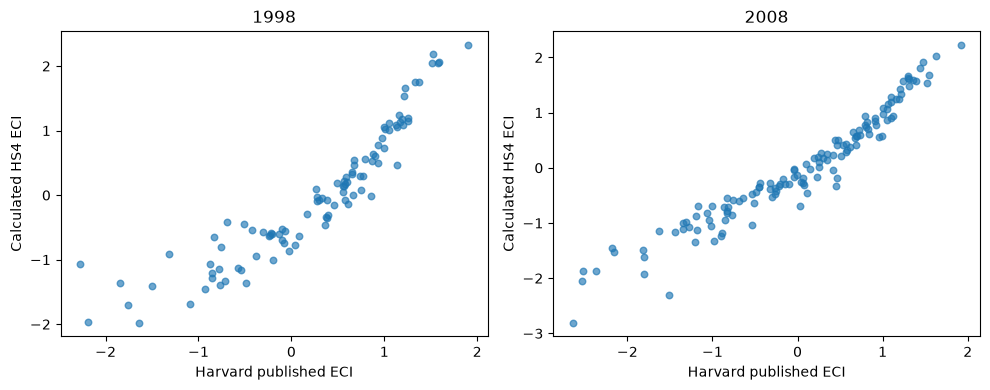

In [7]:
published = cy[['iso3', 'year', 'eci_hs', 'diversity_hs']]
validation_rows, disagreement_rows = [], []
for network, data in [('threshold', metrics), ('broad', broad_metrics)]:
    joined = data.merge(published, on=['iso3', 'year'], how='left', validate='one_to_one')
    for year, g in joined.groupby('year'):
        a = g.dropna(subset=['eci', 'eci_hs'])
        validation_rows.append({'year': year, 'network': network, 'matched_countries': len(a),
            'unmatched_eci': int(g.eci_hs.isna().sum()),
            'eci_pearson': a.eci.corr(a.eci_hs),
            'eci_spearman': a.eci.corr(a.eci_hs, method='spearman'),
            'diversity_spearman': a.diversity.corr(a.diversity_hs, method='spearman')})
        if network == 'threshold' and year in [1998, 2008]:
            a = a.copy()
            a['computed_rank'] = a.eci.rank(ascending=False)
            a['published_rank'] = a.eci_hs.rank(ascending=False)
            a['absolute_rank_difference'] = (a.computed_rank - a.published_rank).abs()
            disagreement_rows.append(a.nlargest(8, 'absolute_rank_difference'))
validation = pd.DataFrame(validation_rows)
validation.to_csv(OUT / 'eci_validation.csv', index=False)
disagreements = pd.concat(disagreement_rows, ignore_index=True)
disagreements.to_csv(OUT / 'eci_rank_disagreements.csv', index=False)
display(validation)
display(disagreements[['iso3', 'year', 'eci', 'eci_hs', 'computed_rank', 'published_rank', 'absolute_rank_difference']])
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, year in zip(axes, [1998, 2008]):
    g = metrics.loc[metrics.year.eq(year)].merge(published, on=['iso3', 'year']).dropna(subset=['eci_hs'])
    ax.scatter(g.eci_hs, g.eci, alpha=.65, s=22)
    ax.set(xlabel="Harvard published ECI", ylabel='Calculated HS4 ECI', title=str(year))
fig.tight_layout()
fig.savefig(OUT / 'eci_validation.png', dpi=160)
plt.show()


## Ranking stability

Spearman correlation between adjacent years, restricted to countries with a score in both years. High stability alone does not establish predictive value; country entry and exit are reported through the paired sample size.


In [8]:
measure_columns = ['diversity', 'entropy', 'hhi', 'eci']
stability_rows = []
for a, b in [(1997, 1998), (1998, 1999), (2007, 2008), (2008, 2009)]:
    pair = metrics.loc[metrics.year.eq(a)].merge(metrics.loc[metrics.year.eq(b)], on='iso3', suffixes=('_a', '_b'))
    for measure in measure_columns:
        g = pair.dropna(subset=[measure+'_a', measure+'_b'])
        stability_rows.append({'year_a': a, 'year_b': b, 'measure': measure,
            'paired_countries': len(g), 'spearman': g[measure+'_a'].corr(g[measure+'_b'], method='spearman')})
stability = pd.DataFrame(stability_rows)
stability.to_csv(OUT / 'rank_stability.csv', index=False)
display(stability)


,year_a,year_b,measure,paired_countries,spearman
0,1997,1998,diversity,98,0.962873
1,1997,1998,entropy,98,0.964106
2,1997,1998,hhi,98,0.950169
3,1997,1998,eci,98,0.981116
4,1998,1999,diversity,96,0.983911
5,1998,1999,entropy,96,0.987819
6,1998,1999,hhi,96,0.986489
7,1998,1999,eci,96,0.981104
8,2007,2008,diversity,131,0.990787
9,2007,2008,entropy,131,0.984461


## Step 3: the first growth-forecast horse race

All models share the same complete-case samples. Scores use starting-year exports; outcomes are the subsequent decade's annualized log growth in real PPP GDP per person. The baseline contains initial log income and resource rents. Each measure is entered linearly without outcome-driven transformations. A joint ECI + diversity model checks whether ECI adds information beyond product count.

All model parameters, including regressor scaling, are fitted on training observations only. Test R² uses the test sample mean as its descriptive denominator; improvements in test mean squared error are relative to the fitted baseline's predictions. HC1 coefficient uncertainty concerns training regressions. Paired bootstrap intervals below concern the held-out countries only and do not establish robustness across decades.


In [9]:
comparison = windows.merge(metrics.rename(columns={'year': 'start'}), on=['iso3', 'start'], how='left', validate='one_to_one')
needed = ['growth', 'log_initial_income', 'resource_rents_pct_gdp', 'diversity', 'entropy', 'hhi', 'eci', 'eci_hs']
complete = comparison[needed].notna().all(axis=1)
exclusions = comparison.loc[~complete, ['iso3', 'start'] + needed]
exclusions.to_csv(OUT / 'model_sample_exclusions.csv', index=False)
comparison = comparison.loc[complete].copy()
train = comparison.loc[comparison.start.eq(1998)].copy()
test = comparison.loc[comparison.start.eq(2008)].copy()
assert len(train) > 0 and len(test) > 0
print('Common training sample:', len(train), '| Common test sample:', len(test), '| Excluded:', len(exclusions))
base = ['log_initial_income', 'resource_rents_pct_gdp']
models = {'Baseline': [], 'Diversity': ['diversity'], 'Entropy': ['entropy'], 'HHI': ['hhi'],
          'Calculated ECI': ['eci'], 'Harvard ECI': ['eci_hs'], 'ECI + diversity': ['eci', 'diversity']}
results, coefficients, predictions = [], [], []
fitted_models = {}
for label, extra in models.items():
    cols = base + extra
    mean, sd = train[cols].mean(), train[cols].std(ddof=0)
    assert sd.gt(0).all()
    Xtrain = sm.add_constant((train[cols] - mean) / sd, has_constant='add')
    Xtest = sm.add_constant((test[cols] - mean) / sd, has_constant='add')
    fit = sm.OLS(train.growth, Xtrain).fit(cov_type='HC1')
    predicted = fit.predict(Xtest)
    fitted_models[label] = fit
    errors = test.growth.to_numpy() - predicted.to_numpy()
    mse = np.mean(errors**2)
    results.append({'model': label, 'n_train': len(train), 'n_test': len(test),
        'train_r2': fit.rsquared, 'train_adjusted_r2': fit.rsquared_adj,
        'test_rmse': np.sqrt(mse), 'test_mae': np.mean(np.abs(errors)),
        'test_r2': 1 - np.sum(errors**2) / np.sum((test.growth - test.growth.mean())**2)})
    for term in fit.params.index:
        interval = fit.conf_int().loc[term]
        coefficients.append({'model': label, 'term': term, 'coefficient': fit.params[term],
            'hc1_se': fit.bse[term], 'pvalue': fit.pvalues[term], 'ci_low': interval.iloc[0], 'ci_high': interval.iloc[1]})
    predictions.append(pd.DataFrame({'iso3': test.iso3.to_numpy(), 'model': label,
        'actual_growth': test.growth.to_numpy(), 'predicted_growth': predicted.to_numpy(), 'error': errors}))
results = pd.DataFrame(results)
baseline = results.loc[results.model.eq('Baseline')].iloc[0]
results['train_r2_gain_vs_baseline'] = results.train_r2 - baseline.train_r2
results['test_mse_improvement_pct'] = 100 * (1 - results.test_rmse**2 / baseline.test_rmse**2)
results.to_csv(OUT / 'initial_model_comparison.csv', index=False)
coefficients = pd.DataFrame(coefficients)
coefficients.to_csv(OUT / 'training_coefficients_hc1.csv', index=False)
predictions = pd.concat(predictions, ignore_index=True)
predictions.to_csv(OUT / 'test_predictions.csv', index=False)
comparison.to_csv(OUT / 'model_country_windows.csv', index=False)
display(results.round(4))
display(coefficients.loc[~coefficients.term.isin(['const'] + base)].round(4))


Common training sample: 95 | Common test sample: 129 | Excluded: 0


,model,n_train,n_test,train_r2,train_adjusted_r2,test_rmse,test_mae,test_r2,train_r2_gain_vs_baseline,test_mse_improvement_pct
0,Baseline,95,129,0.0948,0.0752,2.1645,1.6143,0.0632,0.0000,0.0000
1,Diversity,95,129,0.1196,0.0906,2.1326,1.6440,0.0906,0.0248,2.9252
2,Entropy,95,129,0.1393,0.1110,2.1409,1.6787,0.0834,0.0445,2.1647
3,HHI,95,129,0.0956,0.0658,2.1287,1.6034,0.0939,0.0008,3.2832
4,Calculated ECI,95,129,0.1442,0.1160,2.1147,1.6431,0.1058,0.0494,4.5493
5,Harvard ECI,95,129,0.2405,0.2154,2.1364,1.6932,0.0873,0.1456,2.5814
6,ECI + diversity,95,129,0.1462,0.1083,2.1121,1.6512,0.1080,0.0514,4.7836


,model,term,coefficient,hc1_se,pvalue,ci_low,ci_high
6,Diversity,diversity,0.5319,0.3186,0.0950,-0.0925,1.1563
10,Entropy,entropy,0.9609,0.4119,0.0196,0.1536,1.7681
14,HHI,hhi,-0.1385,0.4798,0.7728,-1.0789,0.8019
18,Calculated ECI,eci,0.9303,0.3623,0.0102,0.2202,1.6403
22,Harvard ECI,eci_hs,1.5947,0.3515,0.0000,0.9058,2.2835
26,ECI + diversity,eci,0.8102,0.4477,0.0703,-0.0672,1.6876
27,ECI + diversity,diversity,0.1802,0.3889,0.6430,-0.5819,0.9424


,comparison,mean_mse_reduction,paired_bootstrap_ci_low,paired_bootstrap_ci_high
0,Calculated ECI versus diversity,0.0761,-0.2854,0.4556


,model,mean_mse_reduction_vs_baseline,paired_bootstrap_ci_low,paired_bootstrap_ci_high
0,Diversity,0.1370,-0.3186,0.6425
1,Entropy,0.1014,-0.7710,1.0888
2,HHI,0.1538,-0.0006,0.3430
3,Calculated ECI,0.2131,-0.2720,0.7562
4,Harvard ECI,0.1209,-0.5869,0.8771
5,ECI + diversity,0.2241,-0.2952,0.8400


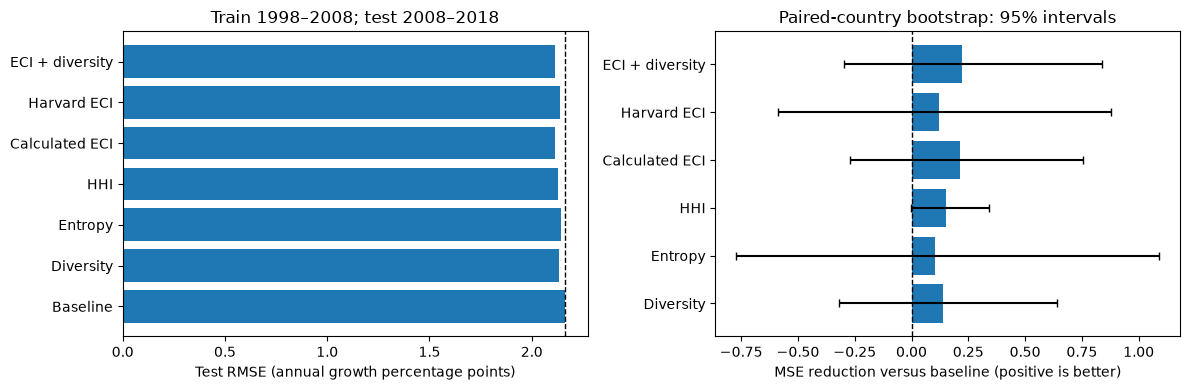

In [10]:
# Resample held-out countries as paired observations across all models.
wide = predictions.pivot(index='iso3', columns='model', values='error')
rng = np.random.default_rng(20261113)
draws = rng.integers(0, len(wide), size=(3000, len(wide)))
uncertainty_rows = []
for label in models:
    if label == 'Baseline':
        continue
    difference = wide.Baseline.to_numpy()**2 - wide[label].to_numpy()**2
    boots = difference[draws].mean(axis=1)
    lo, hi = np.quantile(boots, [.025, .975])
    uncertainty_rows.append({'model': label, 'mean_mse_reduction_vs_baseline': difference.mean(),
        'paired_bootstrap_ci_low': lo, 'paired_bootstrap_ci_high': hi})
uncertainty = pd.DataFrame(uncertainty_rows)
uncertainty.to_csv(OUT / 'paired_test_error_intervals.csv', index=False)
# A paired comparison directly tests the project's key ECI-versus-diversity question.
difference = wide['Diversity'].to_numpy()**2 - wide['Calculated ECI'].to_numpy()**2
lo, hi = np.quantile(difference[draws].mean(axis=1), [.025, .975])
direct_comparison = pd.DataFrame([{'comparison': 'Calculated ECI versus diversity',
    'mean_mse_reduction': difference.mean(), 'paired_bootstrap_ci_low': lo,
    'paired_bootstrap_ci_high': hi}])
direct_comparison.to_csv(OUT / 'eci_vs_diversity_interval.csv', index=False)
display(direct_comparison.round(4))
display(uncertainty.round(4))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].barh(results.model, results.test_rmse)
axes[0].axvline(baseline.test_rmse, color='black', linestyle='--', linewidth=1)
axes[0].set(xlabel='Test RMSE (annual growth percentage points)', title='Train 1998–2008; test 2008–2018')
axes[1].barh(uncertainty.model, uncertainty.mean_mse_reduction_vs_baseline)
axes[1].errorbar(uncertainty.mean_mse_reduction_vs_baseline, uncertainty.model,
    xerr=np.array([uncertainty.mean_mse_reduction_vs_baseline - uncertainty.paired_bootstrap_ci_low,
                  uncertainty.paired_bootstrap_ci_high - uncertainty.mean_mse_reduction_vs_baseline]),
    fmt='none', color='black', capsize=3)
axes[1].axvline(0, color='black', linestyle='--', linewidth=1)
axes[1].set(xlabel='MSE reduction versus baseline (positive is better)', title='Paired-country bootstrap: 95% intervals')
fig.tight_layout()
fig.savefig(OUT / 'initial_forecast_comparison.png', dpi=160)
plt.show()


## Sensitivity: broader trade-network universe

Recompute the same four measures using all positive-export reporters. Evaluate on the intersection of available scores, keeping each alternative model's training and test countries identical to the primary comparison. This tests network construction, not alternative GDP outcomes or forecast periods.


In [11]:
broad_comparison = windows.merge(broad_metrics.rename(columns={'year': 'start'}), on=['iso3', 'start'], how='left', validate='one_to_one')
common_keys = set(zip(comparison.iso3, comparison.start))
broad_comparison = broad_comparison.loc[[(c, y) in common_keys for c, y in zip(broad_comparison.iso3, broad_comparison.start)]]
assert broad_comparison[needed].notna().all().all()
network_rows = []
for label, extra in models.items():
    tr = broad_comparison.loc[broad_comparison.start.eq(1998)]
    te = broad_comparison.loc[broad_comparison.start.eq(2008)]
    cols = base + extra
    mean, sd = tr[cols].mean(), tr[cols].std(ddof=0)
    fit = sm.OLS(tr.growth, sm.add_constant((tr[cols]-mean)/sd, has_constant='add')).fit(cov_type='HC1')
    prediction = fit.predict(sm.add_constant((te[cols]-mean)/sd, has_constant='add'))
    network_rows.append({'model': label, 'n_train': len(tr), 'n_test': len(te),
        'broad_network_test_rmse': np.sqrt(np.mean((te.growth-prediction)**2))})
network_sensitivity = results[['model', 'test_rmse']].merge(pd.DataFrame(network_rows), on='model')
network_sensitivity.to_csv(OUT / 'network_sensitivity.csv', index=False)
display(network_sensitivity.round(4))


,model,test_rmse,n_train,n_test,broad_network_test_rmse
0,Baseline,2.1645,95,129,2.1645
1,Diversity,2.1326,95,129,2.1329
2,Entropy,2.1409,95,129,2.1409
3,HHI,2.1287,95,129,2.1287
4,Calculated ECI,2.1147,95,129,2.0021
5,Harvard ECI,2.1364,95,129,2.1364
6,ECI + diversity,2.1121,95,129,2.0030


## Findings from this first comparison

The following text is generated from the tables above so its numerical claims remain tied to executed results. These are initial findings for one held-out decade; they are not the final Project 3 recommendation.


In [12]:
from IPython.display import Markdown
r = results.set_index('model')
v = validation.loc[validation.network.eq('threshold') & validation.year.isin([1998, 2008])]
best = results.loc[results.test_rmse.idxmin()]
interval_eci = uncertainty.set_index('model').loc['Calculated ECI']
direct = direct_comparison.iloc[0]
broad_eci = network_sensitivity.set_index('model').loc['Calculated ECI', 'broad_network_test_rmse']
findings = f"""- **Coverage:** {len(train)} common training countries and {len(test)} common test countries; {len(exclusions)} preliminary observations excluded for missing compared measures.
- **ECI validation:** primary-network Pearson correlations with Harvard are {v.eci_pearson.min():.3f}–{v.eci_pearson.max():.3f}; rank correlations are {v.eci_spearman.min():.3f}–{v.eci_spearman.max():.3f}. Check the disagreement table before treating this as exact replication.
- **Held-out growth errors:** baseline RMSE is {r.loc['Baseline', 'test_rmse']:.3f}, calculated ECI {r.loc['Calculated ECI', 'test_rmse']:.3f}, and diversity {r.loc['Diversity', 'test_rmse']:.3f} annual percentage points. The smallest observed error belongs to **{best['model']}** ({best.test_rmse:.3f}); this ranking alone does not establish a reliable advantage.
- **ECI versus baseline uncertainty:** mean squared-error reduction is {interval_eci.mean_mse_reduction_vs_baseline:.3f}, with a paired-country 95% bootstrap interval of [{interval_eci.paired_bootstrap_ci_low:.3f}, {interval_eci.paired_bootstrap_ci_high:.3f}]. Positive reductions favor adding ECI. This interval describes these test countries, not uncertainty across future decades.
- **Metric dependence:** calculated ECI's test MAE is {r.loc['Calculated ECI', 'test_mae']:.3f}, compared with baseline {r.loc['Baseline', 'test_mae']:.3f}. Thus its lower RMSE does not mean lower error under every scoring rule.
- **ECI versus diversity:** the paired mean squared-error reduction is {direct.mean_mse_reduction:.3f}, with a 95% interval of [{direct.paired_bootstrap_ci_low:.3f}, {direct.paired_bootstrap_ci_high:.3f}]. Positive values favor ECI; an interval spanning zero does not establish that it is better.
- **Network sensitivity:** using all positive-export reporters changes calculated ECI's test RMSE to {broad_eci:.3f}. This dependence on network construction warrants further checks; the alternative was not chosen as a new winner after viewing outcomes.
- **What this does not show:** no causal effect, final measure winner, or validation of the lab's grouped ECI has been established. One forecast period, revised data, network choices, and assumed zero exports for absent product cells limit interpretation.
"""
display(Markdown(findings))
(OUT / 'initial_findings.md').write_text('# Project 3 — initial horse race\n\n' + findings)


- **Coverage:** 95 common training countries and 129 common test countries; 0 preliminary observations excluded for missing compared measures.
- **ECI validation:** primary-network Pearson correlations with Harvard are 0.920–0.963; rank correlations are 0.968–0.982. Check the disagreement table before treating this as exact replication.
- **Held-out growth errors:** baseline RMSE is 2.164, calculated ECI 2.115, and diversity 2.133 annual percentage points. The smallest observed error belongs to **ECI + diversity** (2.112); this ranking alone does not establish a reliable advantage.
- **ECI versus baseline uncertainty:** mean squared-error reduction is 0.213, with a paired-country 95% bootstrap interval of [-0.272, 0.756]. Positive reductions favor adding ECI. This interval describes these test countries, not uncertainty across future decades.
- **Metric dependence:** calculated ECI's test MAE is 1.643, compared with baseline 1.614. Thus its lower RMSE does not mean lower error under every scoring rule.
- **ECI versus diversity:** the paired mean squared-error reduction is 0.076, with a 95% interval of [-0.285, 0.456]. Positive values favor ECI; an interval spanning zero does not establish that it is better.
- **Network sensitivity:** using all positive-export reporters changes calculated ECI's test RMSE to 2.002. This dependence on network construction warrants further checks; the alternative was not chosen as a new winner after viewing outcomes.
- **What this does not show:** no causal effect, final measure winner, or validation of the lab's grouped ECI has been established. One forecast period, revised data, network choices, and assumed zero exports for absent product cells limit interpretation.


1761

## Extension: complete the remaining Project 3 sequence

The following sections implement the next planned stages in order. The earlier results remain the initial comparison; the extended tables below provide the wider evidence for the final recommendation. Supporting calculations live in `juliawang/project3_horse_race.py` so all years use the same implementation.


## 1. Product aggregation: HS4 → HS2 → lab groups

Reconstruct every level from the same goods records and same year-specific network. Keep the lab's documented chapter mapping unchanged. The 18-group reconstruction includes overlapping exports and a chapter-99 proxy; it does **not** recreate actual service exports. Its category totals therefore need not sum to goods exports. Removing the aggregate changes both duplication and product coverage.

To isolate aggregation on the 17-group coverage, also calculate HS4 ECI using only products assigned to those 17 groups. Compare that score directly with 17-group ECI. The mapping is imported from the documented `LAB_GROUPS` constant; no nightly scores or regression results are reused.

The next cell computes all measures for 1995–2019 once, including the alternatives needed by Section 2, then estimates the designs used in Sections 3–4. The full verified source is local and requires no new download. The assumption that absent product records are zero reported exports remains in force.


Computed 1995 countries 100


Computed 1996 countries 98


Computed 1997 countries 104


Computed 1998 countries 99


Computed 1999 countries 98


Computed 2000 countries 106


... (18 outputs left out)

Computed 2019 countries 141


Completed 8 designs.


,year,measure,countries,nonzero_categories,sum_to_goods_ratio
12,1998,eci_hs2,99,97,1.000000
13,1998,eci_groups18_goods,99,18,1.177807
14,1998,eci_groups17_goods,99,17,0.842109
15,1998,eci_hs4_matched17,99,1133,0.842109
52,2008,eci_hs2,133,97,1.000000
53,2008,eci_groups18_goods,133,18,1.177773
54,2008,eci_groups17_goods,133,17,0.872504
55,2008,eci_hs4_matched17,133,1133,0.872504


,measure,n_train,n_test,train_r2,r2_gain,rmse,mae
0,baseline,95,129,0.0948,0.0000,2.1645,1.6143
4,eci_hs4,95,129,0.1442,0.0494,2.1147,1.6431
5,eci_hs2,95,129,0.1149,0.0201,2.1243,1.6240
6,eci_groups18_goods,95,129,0.0949,0.0000,2.1713,1.6188
7,eci_groups17_goods,95,129,0.0949,0.0001,2.1563,1.6100
8,eci_hs4_matched17,95,129,0.1480,0.0532,2.1176,1.6489


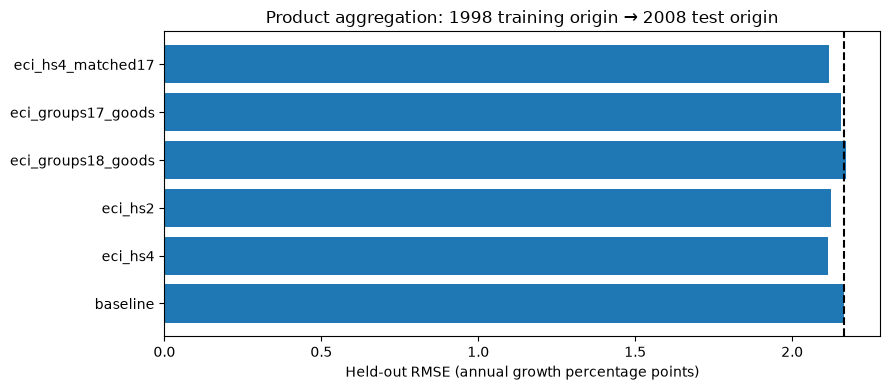

In [13]:
import importlib
import sys
sys.path.insert(0, str(ROOT / 'juliawang'))
import project3_horse_race as full_project
importlib.reload(full_project)
full_results = full_project.run()
FULL = OUT / 'full'
primary_results = full_results.loc[full_results.design.eq('primary_1998_2008')].copy()
coverage_full = pd.read_csv(FULL / 'aggregation_coverage.csv')
spectral_full = pd.read_csv(FULL / 'spectral_diagnostics.csv')
assert spectral_full.components.eq(1).all()
assert spectral_full.gap.gt(1e-8).all()
# The expanded implementation must reproduce the initial standard-ECI result.
assert np.isclose(primary_results.set_index('measure').loc['eci_hs4','rmse'],
                  results.set_index('model').loc['Calculated ECI','test_rmse'])
display(coverage_full.loc[coverage_full.year.isin([1998, 2008])])
aggregation_names = ['baseline','eci_hs4','eci_hs2','eci_groups18_goods','eci_groups17_goods','eci_hs4_matched17']
display(primary_results.loc[primary_results.measure.isin(aggregation_names),
    ['measure','n_train','n_test','train_r2','r2_gain','rmse','mae']].round(4))
fig, ax = plt.subplots(figsize=(9,4))
g = primary_results.loc[primary_results.measure.isin(aggregation_names)].set_index('measure').reindex(aggregation_names)
ax.barh(g.index, g.rmse)
ax.axvline(g.loc['baseline','rmse'],color='black',linestyle='--')
ax.set(xlabel='Held-out RMSE (annual growth percentage points)',title='Product aggregation: 1998 training origin → 2008 test origin')
fig.tight_layout(); fig.savefig(FULL / 'granularity_comparison.png',dpi=160); plt.show()


## 2. Alternative measures and numerical diagnostics

**Continuous RCA:** use `log(1+RCA)` as nonnegative weights in the same normalized spectral construction as ECI. This is a specified continuous-RCA variant, not a claim that every possible variant has been tested.

**Fitness:** use simultaneous country-Fitness and product-complexity updates on the binary RCA matrix, normalizing each vector to mean one after each iteration. Compare log10 Fitness after 200 and 500 iterations. Record changes in log Fitness, numerical floors and ranking agreement. If values have not converged, interpret these as finite-iteration predictors; rank agreement alone does not establish convergence. A numerical floor of 1e−250 guards reciprocal overflow, with counts reported.

No alternative's settings were chosen to minimize test errors. Every model uses the same complete-case sample within its design.


In [14]:
fitness_full = pd.read_csv(FULL / 'fitness_diagnostics.csv')
display(fitness_full.groupby('iterations').agg(
    country_year_sets=('year','size'), converged_sets=('converged_log_tolerance_1e_8','sum'),
    maximum_log_update=('max_log10_update','max'), maximum_floor_count=('floor_countries','max')))
display(fitness_full.loc[fitness_full.year.isin([1998,2008])])
stability_full = pd.read_csv(FULL / 'stability.csv')
stability_summary = stability_full.groupby('measure').agg(
    mean_rank_stability=('spearman','mean'), minimum_rank_stability=('spearman','min'))
full_table = primary_results.merge(stability_summary,on='measure',how='left')
full_table.to_csv(FULL / 'primary_summary_with_stability.csv',index=False)
display(full_table[['measure','n_train','n_test','train_r2','r2_gain','rmse','mae','mean_rank_stability']].round(4))


,country_year_sets,converged_sets,maximum_log_update,maximum_floor_count
iterations,,,,
200,25,0,0.182297,0
500,25,0,0.182297,0


,year,iterations,max_log10_update,floor_countries,converged_log_tolerance_1e_8,rank_correlation_200_500
6,1998,200,0.072115,0,False,NaN
7,1998,500,0.072115,0,False,1.0
26,2008,200,0.046417,0,False,NaN
27,2008,500,0.046416,0,False,1.0


,measure,n_train,n_test,train_r2,r2_gain,rmse,mae,mean_rank_stability
0,baseline,95,129,0.0948,0.0000,2.1645,1.6143,NaN
1,diversity,95,129,0.1196,0.0248,2.1326,1.6440,0.9895
2,entropy,95,129,0.1393,0.0445,2.1409,1.6787,0.9879
3,hhi,95,129,0.0956,0.0008,2.1287,1.6034,0.9754
4,eci_hs4,95,129,0.1442,0.0494,2.1147,1.6431,0.9815
5,eci_hs2,95,129,0.1149,0.0201,2.1243,1.6240,0.9566
6,eci_groups18_goods,95,129,0.0949,0.0000,2.1713,1.6188,0.9428
7,eci_groups17_goods,95,129,0.0949,0.0001,2.1563,1.6100,0.9240
8,eci_hs4_matched17,95,129,0.1480,0.0532,2.1176,1.6489,0.9809
9,eci_continuous,95,129,0.2631,0.1683,2.2200,1.7471,0.9906


## 3. Additional periods and five-year growth

Keep the original 1998→2008 origin comparison. Add rolling-origin ten-year tests starting in **2005, 2008 and 2014**, and five-year tests starting in **2005, 2010, 2015 and 2019**. For each origin T, train only on windows ending by T; forecast growth beginning at T. No test outcomes enter regressors, scaling or training labels.

Training periods can overlap. Cluster training regression standard errors by country and add centered start-year effects; the unseen future period is assigned the training-average period effect. This is an extrapolation assumption. Country bootstraps describe uncertainty within each test design. Do not treat overlapping forecast origins as independent replications or pool their country rows for a naive significance test.

These are retrospective, revised-data comparisons, not historical-vintage forecasts. The additional specifications were implemented after seeing the initial result, so they are robustness exploration rather than preregistered confirmation.


,design,measure,n_train,n_test,rmse,mae,mse_improvement_pct
0,primary_1998_2008,baseline,95,129,2.1645,1.6143,0.0000
1,primary_1998_2008,diversity,95,129,2.1326,1.6440,2.9252
2,primary_1998_2008,entropy,95,129,2.1409,1.6787,2.1647
3,primary_1998_2008,hhi,95,129,2.1287,1.6034,3.2832
4,primary_1998_2008,eci_hs4,95,129,2.1147,1.6431,4.5493
...,...,...,...,...,...,...,...
107,rolling_h5_2019,eci_continuous,2315,137,2.9408,1.9003,8.2450
108,rolling_h5_2019,log_fitness200,2315,137,3.0542,1.9970,1.0306
109,rolling_h5_2019,log_fitness500,2315,137,3.0604,2.0028,0.6303
110,rolling_h5_2019,eci_harvard,2315,137,2.8986,1.8523,10.8584


measure,baseline,diversity,eci_continuous,eci_groups17_goods,eci_groups18_goods,eci_harvard,eci_hs2,eci_hs4,eci_hs4_matched17,eci_plus_diversity,entropy,hhi,log_fitness200,log_fitness500
design,,,,,,,,,,,,,,
primary_1998_2008,0.0,2.93,-5.19,0.75,-0.63,2.58,3.68,4.55,4.29,4.78,2.16,3.28,-12.21,-12.90
rolling_h10_2005,0.0,1.04,6.58,-2.06,0.39,3.30,0.57,3.51,3.54,3.51,4.66,1.22,-5.71,-5.86
rolling_h10_2008,0.0,0.25,-6.03,2.34,3.05,1.41,4.47,4.19,4.11,4.22,1.26,1.07,-2.17,-2.22
rolling_h10_2014,0.0,6.00,9.72,2.86,2.50,19.95,1.24,4.77,5.62,5.91,11.62,4.47,0.44,-0.38
rolling_h5_2005,0.0,2.83,14.64,1.77,2.66,5.44,5.45,6.50,6.37,6.66,5.95,3.90,-0.55,-0.74
rolling_h5_2010,0.0,-2.11,-11.67,1.16,1.63,-5.91,0.46,-2.55,-1.31,-2.76,-1.97,1.36,0.07,-0.04
rolling_h5_2015,0.0,7.12,17.96,5.59,5.17,20.39,10.30,9.59,9.43,9.44,14.99,8.07,0.90,0.36
rolling_h5_2019,0.0,4.03,8.25,3.89,3.58,10.86,5.28,4.08,3.91,4.13,8.21,4.51,1.03,0.63


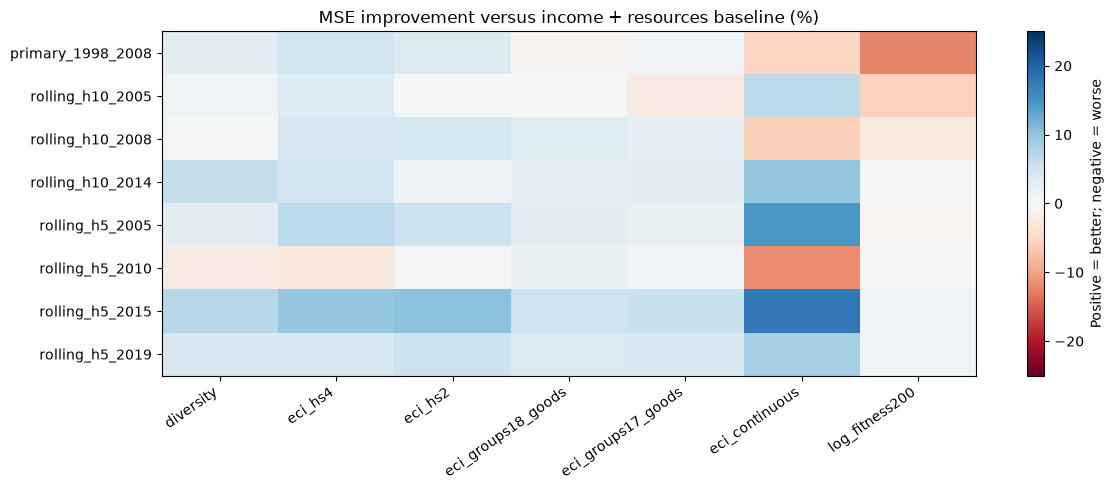

In [15]:
display(full_results[['design','measure','n_train','n_test','rmse','mae','mse_improvement_pct']].round(4))
improvement = full_results.pivot(index='design',columns='measure',values='mse_improvement_pct')
display(improvement.round(2))
fig, ax = plt.subplots(figsize=(12,5))
show = ['diversity','eci_hs4','eci_hs2','eci_groups18_goods','eci_groups17_goods','eci_continuous','log_fitness200']
image = ax.imshow(improvement[show].to_numpy(),cmap='RdBu',vmin=-25,vmax=25,aspect='auto')
ax.set_xticks(range(len(show)),show,rotation=35,ha='right')
ax.set_yticks(range(len(improvement)),improvement.index)
ax.set_title('MSE improvement versus income + resources baseline (%)')
fig.colorbar(image,ax=ax,label='Positive = better; negative = worse')
fig.tight_layout(); fig.savefig(FULL / 'period_robustness.png',dpi=160); plt.show()


## 4. Error concentration and paired uncertainty

Compare ECI and alternatives directly against baseline and diversity using paired-country bootstrap intervals in each design. These exploratory intervals are not corrected for testing multiple measures/periods.

For a diagnostic of error concentration, remove the five largest **baseline** absolute errors from each test set, using the same remaining countries for every model and keeping coefficients fixed. This is an outcome-informed diagnostic, not a new deployable forecast or a preferred sample. Also list the countries contributing the most (positively or negatively) to ECI's error difference. Country-specific causal explanations require separate research; none are inferred solely from prediction residuals.


In [16]:
paired_full = pd.read_csv(FULL / 'paired_intervals.csv')
trimmed_full = pd.read_csv(FULL / 'trimmed_error_diagnostic.csv')
contributions = pd.read_csv(FULL / 'largest_gain_contributions.csv')
display(paired_full.loc[paired_full.design.eq('primary_1998_2008')].round(4))
display(trimmed_full.loc[trimmed_full.measure.isin(['baseline','diversity','eci_hs4'])].round(4))
display(pd.read_csv(FULL / 'largest_baseline_misses.csv').round(4))
display(contributions.loc[contributions.design.eq('primary_1998_2008')].round(4))


,design,measure,comparator,mse_reduction,ci_low,ci_high
0,primary_1998_2008,eci_hs4,baseline,0.2131,-0.2787,0.7548
1,primary_1998_2008,eci_hs2,baseline,0.1723,-0.3273,0.6935
2,primary_1998_2008,eci_groups18_goods,baseline,-0.0295,-0.0573,-0.0077
3,primary_1998_2008,eci_groups17_goods,baseline,0.0352,0.0019,0.0775
4,primary_1998_2008,eci_continuous,baseline,-0.2434,-1.2385,0.7494
5,primary_1998_2008,log_fitness200,baseline,-0.5720,-1.0184,-0.2126
6,primary_1998_2008,eci_hs4,diversity,0.0761,-0.2779,0.4556
7,primary_1998_2008,eci_hs2,diversity,0.0353,-0.4960,0.6000
8,primary_1998_2008,eci_groups18_goods,diversity,-0.1665,-0.6985,0.3161
9,primary_1998_2008,eci_groups17_goods,diversity,-0.1019,-0.5785,0.3438


,design,measure,remaining,trimmed_rmse,trimmed_mse_gain
0,primary_1998_2008,baseline,124,1.7841,0.0000
1,primary_1998_2008,diversity,124,1.7963,-0.0436
7,primary_1998_2008,eci_hs4,124,1.8044,-0.0728
14,rolling_h10_2005,baseline,113,1.7481,0.0000
15,rolling_h10_2005,diversity,113,1.7629,-0.0521
21,rolling_h10_2005,eci_hs4,113,1.7541,-0.0213
28,rolling_h10_2008,baseline,124,1.7446,0.0000
29,rolling_h10_2008,diversity,124,1.7723,-0.0977
35,rolling_h10_2008,eci_hs4,124,1.7636,-0.0669
42,rolling_h10_2014,baseline,130,1.9537,0.0000


,iso3,start,design,measure,actual,prediction,error,absolute_error
0,SYR,2008,primary_1998_2008,baseline,-5.8586,2.9198,-8.7784,8.7784
1,TKM,2008,primary_1998_2008,baseline,6.1103,-1.3293,7.4396,7.4396
2,GNQ,2008,primary_1998_2008,baseline,-6.8477,-1.2397,-5.6080,5.6080
3,GRC,2008,primary_1998_2008,baseline,-2.4267,2.6190,-5.0456,5.0456
4,CHN,2008,primary_1998_2008,baseline,7.1126,2.6016,4.5110,4.5110
5,MDG,2008,primary_1998_2008,baseline,-0.6660,3.7007,-4.3667,4.3667
6,UZB,2008,primary_1998_2008,baseline,5.2998,1.1442,4.1557,4.1557
7,JOR,2008,primary_1998_2008,baseline,-1.2646,2.8013,-4.0659,4.0659
8,MNG,2008,primary_1998_2008,baseline,4.8472,0.7923,4.0549,4.0549
9,ETH,2008,primary_1998_2008,baseline,6.6065,2.8088,3.7977,3.7977


,design,comparator,iso3,mse_gain_contribution,total_mean_mse_gain
0,primary_1998_2008,baseline,TKM,0.1457,0.2131
1,primary_1998_2008,baseline,CHN,0.0844,0.2131
2,primary_1998_2008,baseline,ETH,0.0745,0.2131
3,primary_1998_2008,baseline,UZB,0.0695,0.2131
4,primary_1998_2008,baseline,ZWE,0.0657,0.2131
5,primary_1998_2008,baseline,GRC,0.0521,0.2131
6,primary_1998_2008,baseline,MDG,-0.0501,0.2131
7,primary_1998_2008,baseline,JPN,-0.0400,0.2131
8,primary_1998_2008,baseline,SAU,0.0386,0.2131
9,primary_1998_2008,baseline,GNQ,0.0346,0.2131


## 5. Recommendation from the completed comparisons

The following recommendation is generated from the executed comparison tables. It distinguishes this goods-only grouped reconstruction from the actual reports' services-inclusive data and numerical Fitness estimates from converged solutions.


In [17]:
p = primary_results.set_index('measure')
rolling = full_results.loc[full_results.design.ne('primary_1998_2008')]
counts = rolling.groupby('measure').mse_improvement_pct.apply(lambda x: int(x.gt(0).sum()))
ci = paired_full.loc[paired_full.design.eq('primary_1998_2008') & paired_full.measure.eq('eci_hs4') & paired_full.comparator.eq('diversity')].iloc[0]
cov = coverage_full.loc[coverage_full.year.eq(1998)].set_index('measure')
trim = trimmed_full.loc[trimmed_full.design.eq('primary_1998_2008')].set_index('measure')
recommendation = f"""# Project 3 — recommendation and limits

1. **Use product-level HS4 ECI as a research benchmark, with diversity as a required simpler comparator.** In the original held-out decade, HS4 ECI RMSE is {p.loc['eci_hs4','rmse']:.3f}, diversity {p.loc['diversity','rmse']:.3f}, and baseline {p.loc['baseline','rmse']:.3f}. HS4 ECI improves on baseline in {counts['eci_hs4']} of {rolling.design.nunique()} additional designs. But its primary paired MSE advantage over diversity has a 95% interval [{ci.ci_low:.3f}, {ci.ci_high:.3f}], so a reliable advantage over diversity is not established.

2. **The lab's goods-only grouped ECI is not yet justified as the main growth-forecast score.** Primary test RMSE is {p.loc['eci_groups18_goods','rmse']:.3f} for 18 groups and {p.loc['eci_groups17_goods','rmse']:.3f} without the overlapping aggregate. Compare {p.loc['eci_hs4_matched17','rmse']:.3f} for HS4 using the same product coverage as the 17 groups. This points toward information loss from aggregation in this design, while period results and uncertainty prevent a universal conclusion. This is a reconstruction from goods data, not a complete validation of the services-inclusive report index.

3. **Treat overlap and coverage as separate problems.** In 1998 the 18-group sums are {cov.loc['eci_groups18_goods','sum_to_goods_ratio']:.1%} of goods exports; the 17-group coverage is {cov.loc['eci_groups17_goods','sum_to_goods_ratio']:.1%}. Merely dropping the overlapping category therefore also changes coverage. Do not silently substitute these variants in production reports.

4. **No universal alternative winner emerges.** Continuous log(1+RCA) ECI has primary RMSE {p.loc['eci_continuous','rmse']:.3f} and improves on baseline in {counts['eci_continuous']} of {rolling.design.nunique()} additional designs. Fitness at 200 iterations has RMSE {p.loc['log_fitness200','rmse']:.3f}; no annual network reached the specified log-value convergence tolerance at either recorded iteration count. Its finite-iteration comparison cannot settle the merits of converged Fitness.

5. **Error concentration and scoring choices matter.** After removing the five largest baseline misses (diagnostic only), primary HS4 ECI RMSE is {trim.loc['eci_hs4','trimmed_rmse']:.3f} and baseline {trim.loc['baseline','trimmed_rmse']:.3f}. Inspect the saved paired intervals and contribution tables rather than declaring a winner from average errors alone. Rankings across the alternative designs are exploratory and overlapping periods are not independent evidence.

**Practical recommendation:** retain both product-level ECI and diversity in the lab's validation work; review the grouped mapping before relying on its growth predictions. More out-of-time validation and a resolved Fitness specification would strengthen measure selection. These results do not establish that raising any score causes growth or validates an ECI-maximizing investment budget.
"""
display(Markdown(recommendation))
(FULL / 'recommendation.md').write_text(recommendation)


# Project 3 — recommendation and limits

1. **Use product-level HS4 ECI as a research benchmark, with diversity as a required simpler comparator.** In the original held-out decade, HS4 ECI RMSE is 2.115, diversity 2.133, and baseline 2.164. HS4 ECI improves on baseline in 6 of 7 additional designs. But its primary paired MSE advantage over diversity has a 95% interval [-0.278, 0.456], so a reliable advantage over diversity is not established.

2. **The lab's goods-only grouped ECI is not yet justified as the main growth-forecast score.** Primary test RMSE is 2.171 for 18 groups and 2.156 without the overlapping aggregate. Compare 2.118 for HS4 using the same product coverage as the 17 groups. This points toward information loss from aggregation in this design, while period results and uncertainty prevent a universal conclusion. This is a reconstruction from goods data, not a complete validation of the services-inclusive report index.

3. **Treat overlap and coverage as separate problems.** In 1998 the 18-group sums are 117.8% of goods exports; the 17-group coverage is 84.2%. Merely dropping the overlapping category therefore also changes coverage. Do not silently substitute these variants in production reports.

4. **No universal alternative winner emerges.** Continuous log(1+RCA) ECI has primary RMSE 2.220 and improves on baseline in 5 of 7 additional designs. Fitness at 200 iterations has RMSE 2.293; no annual network reached the specified log-value convergence tolerance at either recorded iteration count. Its finite-iteration comparison cannot settle the merits of converged Fitness.

5. **Error concentration and scoring choices matter.** After removing the five largest baseline misses (diagnostic only), primary HS4 ECI RMSE is 1.804 and baseline 1.784. Inspect the saved paired intervals and contribution tables rather than declaring a winner from average errors alone. Rankings across the alternative designs are exploratory and overlapping periods are not independent evidence.

**Practical recommendation:** retain both product-level ECI and diversity in the lab's validation work; review the grouped mapping before relying on its growth predictions. More out-of-time validation and a resolved Fitness specification would strengthen measure selection. These results do not establish that raising any score causes growth or validates an ECI-maximizing investment budget.


2406